Загрузка датасета

In [366]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('../data/AmesHousing.csv')

Изучение распределения целевой переменной saleprice

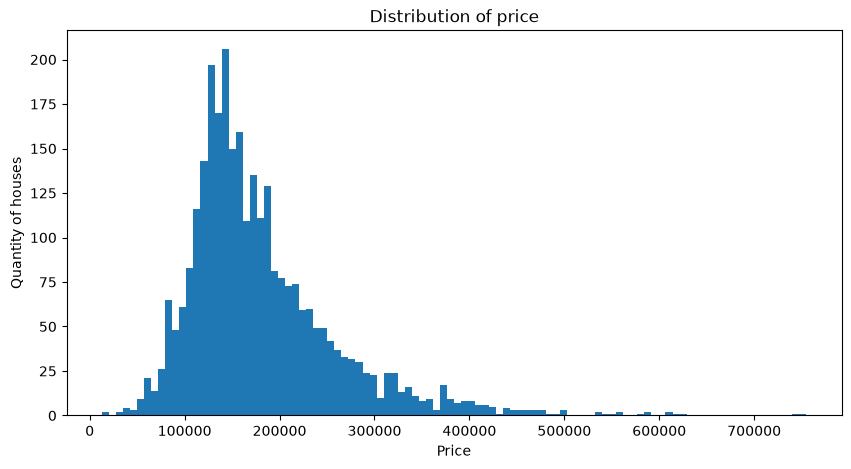

In [367]:
df = df.drop(columns=['Order', 'PID']) # Служебные столбцы
df.columns = df.columns.str.lower().str.replace(' ', '_')
plt.figure(figsize=(10, 5))
plt.hist(df['saleprice'], bins=100)
plt.title('Distribution of price')
plt.xlabel('Price')
plt.ylabel('Quantity of houses')
plt.show()

In [368]:
print(df['saleprice'].skew(), '\n', df['saleprice'].kurt(), '\n', stats.shapiro(df['saleprice']))
# Тяжелый хвост справа, данные не нормальны

1.7435000757376475 
 5.1188999511308975 
 ShapiroResult(statistic=np.float64(0.8762606264935351), pvalue=np.float64(2.3349088329079337e-43))


In [369]:
print(df['saleprice'][df['saleprice'] < 50000].sort_values(), '\n')
print(df['saleprice'][df['saleprice'] > 480000].sort_values())
#

181     12789
1553    13100
726     34900
2843    35000
2880    35311
709     37900
1901    39300
1555    40000
727     44000
708     45000
1302    46500
Name: saleprice, dtype: int64 

422     485000
1691    492000
46      500000
1701    500067
366     501837
2334    535000
15      538000
2330    545224
456     552000
423     555000
2332    556581
433     582933
2450    584500
1637    591587
432     610000
44      611657
1063    615000
2445    625000
1760    745000
1767    755000
Name: saleprice, dtype: int64


Анализ значений, похожих на выбросы

In [370]:
print(df[df['saleprice'] == 12789.0].select_dtypes(include='number').T)
print(df[df['saleprice'] == 755000.0].select_dtypes(include='number').T)
# Признаки в норме, похожих значений в saleprice много, это не выбросы

                     181
ms_subclass         30.0
lot_frontage        68.0
lot_area          9656.0
overall_qual         2.0
overall_cond         2.0
year_built        1923.0
year_remod/add    1970.0
mas_vnr_area         0.0
bsmtfin_sf_1         0.0
bsmtfin_sf_2         0.0
bsmt_unf_sf        678.0
total_bsmt_sf      678.0
1st_flr_sf         832.0
2nd_flr_sf           0.0
low_qual_fin_sf      0.0
gr_liv_area        832.0
bsmt_full_bath       0.0
bsmt_half_bath       0.0
full_bath            1.0
half_bath            0.0
bedroom_abvgr        2.0
kitchen_abvgr        1.0
totrms_abvgrd        5.0
fireplaces           1.0
garage_yr_blt     1928.0
garage_cars          2.0
garage_area        780.0
wood_deck_sf         0.0
open_porch_sf        0.0
enclosed_porch       0.0
3ssn_porch           0.0
screen_porch         0.0
pool_area            0.0
misc_val             0.0
mo_sold              6.0
yr_sold           2010.0
saleprice        12789.0
                     1767
ms_subclass          60.

In [371]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ms_subclass,2930.0,57.387372,42.638025,20.0,20.00,50.0,70.00,190.0
lot_frontage,2440.0,69.224590,23.365335,21.0,58.00,68.0,80.00,313.0
lot_area,2930.0,10147.921843,7880.017759,1300.0,7440.25,9436.5,11555.25,215245.0
overall_qual,2930.0,6.094881,1.411026,1.0,5.00,6.0,7.00,10.0
overall_cond,2930.0,5.563140,1.111537,1.0,5.00,5.0,6.00,9.0
year_built,2930.0,1971.356314,30.245361,1872.0,1954.00,1973.0,2001.00,2010.0
year_remod/add,2930.0,1984.266553,20.860286,1950.0,1965.00,1993.0,2004.00,2010.0
mas_vnr_area,2907.0,101.896801,179.112611,0.0,0.00,0.0,164.00,1600.0
bsmtfin_sf_1,2929.0,442.629566,455.590839,0.0,0.00,370.0,734.00,5644.0
bsmtfin_sf_2,2929.0,49.722431,169.168476,0.0,0.00,0.0,0.00,1526.0


Признак lot_area распределен подозрительно, среднее больше медианы в ~10,5 раз, построю график распределения и подробнее изучу признак

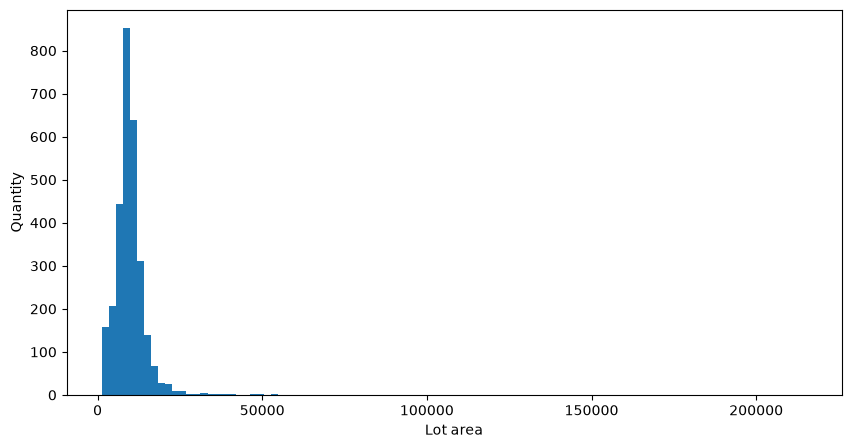

In [372]:
plt.figure(figsize=(10, 5))
plt.hist(df['lot_area'], bins=100)
plt.xlabel('Lot area')
plt.ylabel('Quantity')
plt.show()

In [ ]:
print(df['lot_area'].skew(), '\n', df['lot_area'].kurt())
# Очень тяжелые хвосты

12.820898171092686 
 265.02367060293284


In [405]:
print(df[['lot_area', 'saleprice']][df['lot_area'] < 2000].sort_values('saleprice')) # маленькое значение lot_area в датасете не редкость
print(df[df['lot_area'] == 1300.0].select_dtypes(include='number').T) # похожих значений много, признаки в норме, не выброс

      lot_area  saleprice
2920      1894      71000
2913      1470      73000
2290      1890      75190
330       1491      75500
329       1476      76000
2914      1484      79400
2918      1526      79500
977       1477      80000
1600      1890      81000
2366      1953      83000
326       1974      83500
2289      1936      84500
1043      1680      85400
332       1890      85500
2285      1504      85500
975       1526      86000
2917      1533      87550
31        1680      88000
331       1900      88250
2370      1680      89000
1044      1680      89500
2919      1936      90500
973       1596      91000
2368      1680      91500
2916      1533      92000
2287      1495      93900
2372      1680      94500
1597      1596      94900
29        1680      96000
978       1533      97000
405       1680      97000
1599      1477      98000
1040      1680     100000
1041      1890     100500
1039      1680     103400
1596      1974     105000
30        1680     105500
1042      18

In [406]:
q1 = df['lot_area'].quantile(0.25)
q3 = df['lot_area'].quantile(0.75)
iqr = q3 - q1
upper = q3 + 3*iqr
print(upper, '— верхняя граница по правилу 3 IQR, после которой идут статистические выбросы\n')
print((df['lot_area'] > upper).sum(), '— количество таких выбросов. Проверю природу некоторых из них')
# print(df['lot_area'][df['lot_area'] > upper]) - все выбросы по правилу 3 IQR

23900.25 — верхняя граница по правилу 3 IQR, после которой идут статистические выбросы

53 — количество таких выбросов. Проверю природу некоторых из них


In [407]:
print(df[df['lot_area'] == 31770].select_dtypes(include='number').T)
print(df[df['lot_area'] == 215245].select_dtypes(include='number').T)
# Очевидных причин по которым эти записи можно отнести к выбросам нет, поэтому удалять их не стану
# В дальнейшем проведу анализ, насколько модели справляются со всем признаком

                        0
ms_subclass          20.0
lot_frontage        141.0
lot_area          31770.0
overall_qual          6.0
overall_cond          5.0
year_built         1960.0
year_remod/add     1960.0
mas_vnr_area        112.0
bsmtfin_sf_1        639.0
bsmtfin_sf_2          0.0
bsmt_unf_sf         441.0
total_bsmt_sf      1080.0
1st_flr_sf         1656.0
2nd_flr_sf            0.0
low_qual_fin_sf       0.0
gr_liv_area        1656.0
bsmt_full_bath        1.0
bsmt_half_bath        0.0
full_bath             1.0
half_bath             0.0
bedroom_abvgr         3.0
kitchen_abvgr         1.0
totrms_abvgrd         7.0
fireplaces            2.0
garage_yr_blt      1960.0
garage_cars           2.0
garage_area         528.0
wood_deck_sf        210.0
open_porch_sf        62.0
enclosed_porch        0.0
3ssn_porch            0.0
screen_porch          0.0
pool_area             0.0
misc_val              0.0
mo_sold               5.0
yr_sold            2010.0
saleprice        215000.0
            

Анализ пропусков и поиск категориальных столбцов

In [408]:
metrics = pd.DataFrame({
    'dtypes': df.dtypes,
    'missing_%': df.isna().mean() * 100,
    'missing': df.isna().sum(),
    'nunique': df.nunique()
}).sort_values('nunique')
print(metrics[metrics['dtypes'] == 'int64'])
print(metrics[metrics['dtypes'] == 'float64'])
print(metrics[metrics['dtypes'] == 'str'])

                dtypes  missing_%  missing  nunique
half_bath        int64        0.0        0        3
kitchen_abvgr    int64        0.0        0        4
full_bath        int64        0.0        0        5
fireplaces       int64        0.0        0        5
yr_sold          int64        0.0        0        5
bedroom_abvgr    int64        0.0        0        8
overall_cond     int64        0.0        0        9
overall_qual     int64        0.0        0       10
mo_sold          int64        0.0        0       12
totrms_abvgrd    int64        0.0        0       14
pool_area        int64        0.0        0       14
ms_subclass      int64        0.0        0       16
3ssn_porch       int64        0.0        0       31
low_qual_fin_sf  int64        0.0        0       36
misc_val         int64        0.0        0       38
year_remod/add   int64        0.0        0       61
year_built       int64        0.0        0      118
screen_porch     int64        0.0        0      121
enclosed_por

In [409]:
missing = (metrics.index[metrics['missing_%'] > 48]).to_list()
print(missing, '\n— признаки, количество пропусков в которых превышает 48%')

['alley', 'mas_vnr_type', 'pool_qc', 'fence', 'misc_feature', 'fireplace_qu'] 
— признаки, количество пропусков в которых превышает 48%


Поиск наиболее коррелирующих признаков

In [410]:
corr = df.corr(numeric_only=True)['saleprice'].sort_values(ascending=False)
print(corr)

saleprice          1.000000
overall_qual       0.799262
gr_liv_area        0.706780
garage_cars        0.647877
garage_area        0.640401
total_bsmt_sf      0.632280
1st_flr_sf         0.621676
year_built         0.558426
full_bath          0.545604
year_remod/add     0.532974
garage_yr_blt      0.526965
mas_vnr_area       0.508285
totrms_abvgrd      0.495474
fireplaces         0.474558
bsmtfin_sf_1       0.432914
lot_frontage       0.357318
wood_deck_sf       0.327143
open_porch_sf      0.312951
half_bath          0.285056
bsmt_full_bath     0.276050
2nd_flr_sf         0.269373
lot_area           0.266549
bsmt_unf_sf        0.182855
bedroom_abvgr      0.143913
screen_porch       0.112151
pool_area          0.068403
mo_sold            0.035259
3ssn_porch         0.032225
bsmtfin_sf_2       0.005891
misc_val          -0.015691
yr_sold           -0.030569
bsmt_half_bath    -0.035835
low_qual_fin_sf   -0.037660
ms_subclass       -0.085092
overall_cond      -0.101697
kitchen_abvgr     -0